# Doctoome – Type 2 Diabetes Awareness Questionnaire: Data Analysis

**Goal:** explore the questionnaire data, assess its quality, clean it, and identify the insights most useful to Doctoome.

**Stack:** Python, DuckDB (SQL directly on the Parquet files), pandas, matplotlib.

**Notebook structure:**
1. **Phase 1 – Exploration & data quality audit** (steps 1–14): understand the tables and detect issues, without changing anything.
2. **Phase 2 – Cleaning** (steps 15–19): build clean tables with `sql/02_clean_tables.sql`.
3. **Phase 3 – Analyses** (steps 20–28): funnel, acquisition, outcomes, trends.
4. **Phase 4 – Visualisations** (steps 29+): charts exported to `outputs/figures/`.

> All data is synthetic. Outcome categories are **fictional analytical categories**, not medical diagnoses.

# Phase 1 – Exploration & data quality audit

## Step 1 – Load the data
Check that the 6 Parquet files can be read and count the rows of each table.

In [1]:
# Step 1: load libraries, connect to DuckDB and count rows per table
import duckdb
import pandas as pd

con = duckdb.connect()                   # in-memory SQL engine
con.execute("SET TimeZone = 'UTC'")      # data is in UTC: display every timestamp in UTC

tables = ["visitors", "sessions", "questionnaire_questions",
          "questionnaire_events", "questionnaire_answers", "questionnaire_outcomes"]

for t in tables:
    n = con.execute(f"SELECT COUNT(*) FROM '../data/{t}.parquet'").fetchone()[0]
    print(f"{t}: {n} rows")

visitors: 20000 rows
sessions: 26000 rows
questionnaire_questions: 5 rows
questionnaire_events: 195816 rows
questionnaire_answers: 68460 rows
questionnaire_outcomes: 11357 rows


**Findings:**
- 20,000 visitors and 26,000 sessions (~1.3 sessions per visitor: some visitors come back).
- 11,357 outcomes, i.e. ~44% of sessions reach a result (raw figure, to be confirmed).
- 68,460 answers vs 11,357 × 5 = 56,785 for completed questionnaires: the surplus comes from abandoned questionnaires and duplicate answers (see step 8).

## Step 2 – Table structure
List the columns of each table and their type (text, number, date…).

In [2]:
# Step 2: show column names and types for each table
for t in tables:
    print(f"===== {t} =====")
    # DESCRIBE returns the column list; keep only name and type
    print(con.execute(f"DESCRIBE SELECT * FROM '../data/{t}.parquet'").df()[["column_name", "column_type"]])
    print()

===== visitors =====
     column_name               column_type
0     visitor_id                   VARCHAR
1     birth_year                    BIGINT
2         gender                   VARCHAR
3         region                   VARCHAR
4  first_seen_at  TIMESTAMP WITH TIME ZONE

===== sessions =====
            column_name               column_type
0            session_id                   VARCHAR
1            visitor_id                   VARCHAR
2    session_started_at  TIMESTAMP WITH TIME ZONE
3    acquisition_source                   VARCHAR
4         campaign_name                   VARCHAR
5           device_type                   VARCHAR
6          landing_page                   VARCHAR
7  is_returning_visitor                   BOOLEAN

===== questionnaire_questions =====
       column_name column_type
0      question_id     VARCHAR
1  question_number      BIGINT
2    question_text     VARCHAR
3    response_type     VARCHAR
4  allowed_answers     VARCHAR

===== questionnaire_event

**Findings:** column types are consistent (IDs as text, `birth_year` as integer, timestamps with time zone, `is_returning_visitor` as boolean). No type conversion needed.

## Step 3 – Data preview
Show a few rows of each table to understand their content.

In [3]:
# Step 3: show the first 5 rows of each table
for t in tables:
    print(f"===== {t} =====")
    display(con.execute(f"SELECT * FROM '../data/{t}.parquet' LIMIT 5").df())

===== visitors =====


,visitor_id,birth_year,gender,region,first_seen_at
0,VIS_00000001,2008,male,Bretagne,2026-08-02 04:29:33.074952+00:00
1,VIS_00000002,1946,female,Hauts-de-France,2026-07-25 11:59:57.752213+00:00
2,VIS_00000003,<NA>,female,Pays de la Loire,2026-06-22 12:37:47.114315+00:00
3,VIS_00000004,1989,other,Provence-Alpes-Côte d'Azur,2026-07-12 02:29:05.408274+00:00
4,VIS_00000005,1989,female,Hauts-de-France,2026-07-10 05:33:03.390070+00:00


===== sessions =====


,session_id,visitor_id,session_started_at,acquisition_source,campaign_name,device_type,landing_page,is_returning_visitor
0,SES_00000001,VIS_00016128,2026-06-01 00:01:59.429044+00:00,social,diabetes_social_awareness,desktop,/health/diabetes-awareness,False
1,SES_00000002,VIS_00012147,2026-06-01 00:07:54.468178+00:00,google_organic,NaN,desktop,/health/diabetes-awareness,False
2,SES_00000003,VIS_00018597,2026-06-01 00:10:06.909833+00:00,google_ads,diabetes_awareness_general,desktop,/health/diabetes-awareness,False
3,SES_00000004,VIS_00006671,2026-06-01 00:14:47.814240+00:00,google_organic,NaN,mobile,/health/diabetes-awareness,False
4,SES_00000005,VIS_00018327,2026-06-01 00:14:55.885097+00:00,chatgpt,NaN,mobile,/health/diabetes-awareness,False


===== questionnaire_questions =====


...

,event_id,session_id,visitor_id,event_timestamp,event_type,question_number
0,EVT_000000001,SES_00000001,VIS_00016128,2026-06-01 00:01:59.429044+00:00,landing_view,<NA>
1,EVT_000000002,SES_00000001,VIS_00016128,2026-06-01 00:02:07.868799+00:00,questionnaire_start,<NA>
2,EVT_000000003,SES_00000001,VIS_00016128,2026-06-01 00:02:11.208955+00:00,question_view,1
3,EVT_000000004,SES_00000001,VIS_00016128,2026-06-01 00:02:35.588484+00:00,question_answer,1
4,EVT_000000005,SES_00000001,VIS_00016128,2026-06-01 00:02:36.940089+00:00,question_view,2


===== questionnaire_answers =====


,answer_id,session_id,visitor_id,question_id,question_number,answer_value,answered_at
0,ANS_000000001,SES_00000001,VIS_00016128,diabetes_q1,1,no,2026-06-01 00:02:35.588484+00:00
1,ANS_000000002,SES_00000002,VIS_00012147,diabetes_q1,1,no,2026-06-01 00:09:23.966499+00:00
2,ANS_000000003,SES_00000002,VIS_00012147,diabetes_q2,2,no,2026-06-01 00:09:48.773896+00:00
3,ANS_000000004,SES_00000003,VIS_00018597,diabetes_q1,1,no,2026-06-01 00:11:09.794015+00:00
4,ANS_000000005,SES_00000003,VIS_00018597,diabetes_q2,2,no,2026-06-01 00:11:33.897800+00:00


===== questionnaire_outcomes =====


,session_id,visitor_id,outcome_category,completed_at
0,SES_00000003,VIS_00018597,no_current_indication,2026-06-01 00:12:52.331208+00:00
1,SES_00000004,VIS_00006671,no_current_indication,2026-06-01 00:16:49.679841+00:00
2,SES_00000008,VIS_00011878,possible_risk,2026-06-01 00:25:13.601379+00:00
3,SES_00000010,VIS_00013989,no_current_indication,2026-06-01 00:29:10.634712+00:00
4,SES_00000011,VIS_00002128,no_current_indication,2026-06-01 00:33:05.062401+00:00


**Findings:**
- `birth_year` has missing values.
- `campaign_name` is empty for `google_organic` and `chatgpt`: expected, these are not paid campaigns.
- `chatgpt` is an acquisition source: part of the traffic comes from AI assistants.
- Q1 asks about a previous diagnosis: it likely drives the `declared_diagnosed` category.

## Step 4 – Column profiling
For each column: min, max, approximate number of distinct values, % of missing values.

In [4]:
# Step 4: SUMMARIZE gives a statistical profile of every column
for t in tables:
    print(f"===== {t} =====")
    display(con.execute(f"SUMMARIZE SELECT * FROM '../data/{t}.parquet'").df()
            [["column_name", "min", "max", "approx_unique", "null_percentage"]])

===== visitors =====


,column_name,min,max,approx_unique,null_percentage
0,visitor_id,VIS_00000001,VIS_00020000,21139,0.00
1,birth_year,1929,2010,69,3.81
2,gender,F,prefer_not_to_say,9,3.26
3,region,Auvergne Rhone Alpes,Île-de-France,19,4.02
4,first_seen_at,2026-06-01 00:01:59.429044+00,2026-08-02 16:44:38.140839+00,17814,0.00


===== sessions =====


,column_name,min,max,approx_unique,null_percentage
0,session_id,SES_00000001,SES_00026000,26953,0.00
1,visitor_id,VIS_00000001,VIS_00020000,21139,0.00
2,session_started_at,2026-06-01 00:01:59.429044+00,2026-08-02 16:44:38.140839+00,24831,0.00
3,acquisition_source,AI Assistant,social,15,0.00
4,campaign_name,diabetes_45plus,diabetes_social_awareness,4,54.16
5,device_type,desktop,tablet,3,0.00
6,landing_page,/health/diabetes-awareness,/health/diabetes-awareness,1,0.00
7,is_returning_visitor,false,true,2,0.00


===== questionnaire_questions =====


...

,column_name,min,max,approx_unique,null_percentage
0,event_id,EVT_000000001,EVT_000195816,203158,0.00
1,session_id,SES_00000001,SES_00026000,26953,0.00
2,visitor_id,VIS_00000001,VIS_00020000,21139,0.00
3,event_timestamp,2026-06-01 00:01:59.429044+00,2026-08-02 16:44:38.140839+00,204149,0.00
4,event_type,landing_view,questionnaire_start,5,0.00
5,question_number,1,5,5,27.64


===== questionnaire_answers =====


,column_name,min,max,approx_unique,null_percentage
0,answer_id,ANS_000000001,ANS_000068460,88499,0.0
1,session_id,SES_00000001,SES_00025999,17603,0.0
2,visitor_id,VIS_00000001,VIS_00020000,13971,0.0
3,question_id,diabetes_q1,diabetes_q5,5,0.0
4,question_number,1,5,5,0.0
5,answer_value,1_to_2_days_per_week,yes,9,0.0
6,answered_at,2026-06-01 00:02:35.588484+00,2026-08-02 16:35:18.867974+00,60930,0.0


===== questionnaire_outcomes =====


,column_name,min,max,approx_unique,null_percentage
0,session_id,SES_00000003,SES_00025999,11770,0.0
1,visitor_id,VIS_00000002,VIS_00019998,11793,0.0
2,outcome_category,declared_diagnosed,possible_risk,3,0.0
3,completed_at,2026-06-01 00:12:52.331208+00,2026-08-02 16:35:20.125069+00,12004,0.0


**Findings:**
- **Data ends on 2 August 2026**, not at the end of August.
- Suspicious columns: `gender` (9 values), `region` (19 values), `acquisition_source` (variants such as `AI Assistant` and `chatgpt`).
- `campaign_name` is 54% empty; `birth_year` ranges from 1929 to 2010 (some visitors are minors) with 3.8% missing.
- `question_number` is 27.6% empty in events: expected (`landing_view`, `start` and `complete` are not linked to a question).
- ⚠️ `approx_unique` is an **estimate**: it was only used to spot suspicious columns, each suspicion was then checked with an exact count.

## Step 5 – Distinct values of categorical columns
List every value and its frequency to spot variants that need to be harmonised.

In [5]:
# Step 5: count each distinct value of the suspicious columns
columns_to_check = [
    ("visitors", "gender"),
    ("visitors", "region"),
    ("sessions", "acquisition_source"),
    ("sessions", "campaign_name"),
    ("questionnaire_answers", "answer_value"),
    ("questionnaire_questions", "question_text"),
]

for table, col in columns_to_check:
    print(f"===== {table}.{col} =====")
    display(con.execute(f"""
        SELECT {col}, COUNT(*) AS nb
        FROM '../data/{table}.parquet'
        GROUP BY {col}
        ORDER BY nb DESC
    """).df())

===== visitors.gender =====


,gender,nb
0,female,9301
1,male,8257
2,NaN,653
3,prefer_not_to_say,512
4,other,284
5,F,283
6,Male,246
7,M,245
8,Female,219


===== visitors.region =====


,region,nb
0,Hauts-de-France,2132
1,Île-de-France,2103
2,Auvergne-Rhône-Alpes,2080
3,Occitanie,2028
4,Grand Est,2022
5,Bretagne,2014
6,Nouvelle-Aquitaine,2014
7,Provence-Alpes-Côte d'Azur,2001
8,Pays de la Loire,1934
9,NaN,804


===== sessions.acquisition_source =====


...

,campaign_name,nb
0,NaN,14081
1,diabetes_awareness_general,3422
2,diabetes_social_awareness,3345
3,diabetes_45plus,3337
4,diabetes_retargeting,1815


===== questionnaire_answers.answer_value =====


,answer_value,nb
0,no,41143
1,yes,10736
2,not_sure,3776
3,3_to_4_days_per_week,3344
4,1_to_2_days_per_week,3045
5,rarely_or_never,2911
6,5_or_more_days_per_week,2875
7,prefer_not_to_say,630


===== questionnaire_questions.question_text =====


,question_text,nb
0,Have you ever been told by a healthcare profes...,1
1,"During the last 3 months, have you frequently ...",1
2,Has a parent or sibling been diagnosed with Ty...,1
3,How often do you usually do at least 30 minute...,1
4,Have you ever been told that your blood sugar ...,1


**Findings:**
- **gender:** `F`/`Female` and `M`/`Male` variants → **993 visitors** to harmonise; 653 missing.
- **region:** lowercase, missing accents or hyphens → **868 visitors** to harmonise; 804 missing. Only 9 regions exist in the data.
- **acquisition_source:** `google`/`Google` (900), `facebook`/`instagram` (442), `ChatGPT`/`AI Assistant` (328) → **1,670 sessions** to regroup.
- `campaign_name`: 4 clean campaigns. `answer_value` (8 values) and `question_text` (5 texts): no issue (the `SUMMARIZE` estimate was wrong).

## Step 6 – Source × campaign consistency
Which campaigns are attached to each source? Used to classify `google`/`Google` and to detect paid sources without a campaign.

In [6]:
# Step 6: cross-tab source x campaign
con.execute("""
    SELECT acquisition_source,
           COALESCE(campaign_name, '(none)') AS campaign,   -- replace NULL with readable text
           COUNT(*) AS nb
    FROM '../data/sessions.parquet'
    GROUP BY acquisition_source, campaign
    ORDER BY acquisition_source, nb DESC
""").df()

,acquisition_source,campaign,nb
0,AI Assistant,(none),165
1,ChatGPT,(none),163
2,Google,(none),450
3,chatgpt,(none),2401
4,direct,(none),1398
5,direct,diabetes_retargeting,219
6,email,diabetes_awareness_general,987
7,email,diabetes_retargeting,720
8,facebook,diabetes_social_awareness,202
9,facebook,diabetes_retargeting,19


**Findings:**
- The 900 `google`/`Google` sessions have **no campaign**, while **100%** of `google_ads` sessions have one → classified as **`google_organic`**.
- `facebook`/`instagram` share the `social` campaigns → regrouped into `social`. `ChatGPT`/`AI Assistant` → `chatgpt`.
- All paid channels have a campaign: paid attribution is reliable.
-  **219 `direct` sessions carry the `diabetes_retargeting` campaign** (illogical) → kept and flagged.

## Step 7 – Duplicates
Check that IDs are unique and that a session has at most one answer per question.

In [7]:
# Step 7: for each table, number of rows vs number of unique keys
checks_duplicates = [
    ("visitors", "visitor_id"),
    ("sessions", "session_id"),
    ("questionnaire_events", "event_id"),
    ("questionnaire_answers", "answer_id"),
    ("questionnaire_outcomes", "session_id"),                  # at most 1 outcome per session
    ("questionnaire_answers", "session_id, question_number"),  # at most 1 answer per question per session
]

for table, key in checks_duplicates:
    r = con.execute(f"""
        SELECT COUNT(*) AS nb_rows,
               COUNT(DISTINCT ({key})) AS nb_unique
        FROM '../data/{table}.parquet'
    """).fetchone()
    print(f"{table} [{key}] : {r[0]} rows, {r[1]} unique -> {r[0] - r[1]} duplicates")

visitors [visitor_id] : 20000 rows, 20000 unique -> 0 duplicates
sessions [session_id] : 26000 rows, 26000 unique -> 0 duplicates
questionnaire_events [event_id] : 195816 rows, 195816 unique -> 0 duplicates


questionnaire_answers [answer_id] : 68460 rows, 68460 unique -> 0 duplicates
questionnaire_outcomes [session_id] : 11357 rows, 11357 unique -> 0 duplicates
questionnaire_answers [session_id, question_number] : 68460 rows, 67763 unique -> 697 duplicates


**Findings:** all IDs are unique, but **697 sessions have two answers to the same question**.

## Step 8 – Nature of the duplicate answers
Is it the same value recorded twice (tracking bug) or a different value (the visitor changed their answer)?

In [8]:
# Step 8: for each duplicated (session, question), are the answers identical?
con.execute("""
    WITH duplicates AS (
        SELECT session_id, question_number,
               COUNT(*)                            AS nb_answers,
               COUNT(DISTINCT answer_value)        AS nb_distinct_values,
               MAX(answered_at) - MIN(answered_at) AS time_gap
        FROM '../data/questionnaire_answers.parquet'
        GROUP BY session_id, question_number
        HAVING COUNT(*) > 1          -- keep duplicates only
    )
    SELECT nb_answers,
           nb_distinct_values,
           COUNT(*)          AS nb_cases,
           MEDIAN(time_gap)  AS median_gap
    FROM duplicates
    GROUP BY nb_answers, nb_distinct_values
    ORDER BY nb_cases DESC
""").df()

,nb_answers,nb_distinct_values,nb_cases,median_gap
0,2,2,697,0 days 00:00:10.404307


**Findings:** all 697 cases have **2 answers with 2 different values, ~10 seconds apart** → not a bug but a **change of mind**.
**Decision:** keep the **most recent answer** (applied in phase 2).

## Step 9 – Answer validity
Is every answer part of the `allowed_answers` of its question?

In [9]:
# Step 9: compare each answer with the list of allowed answers of its question
con.execute("""
    SELECT a.question_number,
           a.answer_value,
           COUNT(*) AS nb,
           list_contains(CAST(q.allowed_answers AS VARCHAR[]), a.answer_value) AS is_allowed
    FROM '../data/questionnaire_answers.parquet' a
    JOIN '../data/questionnaire_questions.parquet' q
      ON a.question_id = q.question_id
    GROUP BY a.question_number, a.answer_value, q.allowed_answers
    ORDER BY a.question_number, nb DESC
""").df()

,question_number,answer_value,nb,is_allowed
0,1,no,13379,True
1,1,yes,1723,True
2,1,prefer_not_to_say,630,True
3,2,no,10416,True
4,2,yes,3041,True
5,2,not_sure,1461,True
6,3,no,9087,True
7,3,yes,3755,True
8,3,not_sure,1212,True
9,4,3_to_4_days_per_week,3344,True


**Findings:**
- **100% of answers are valid** for their question.
- First view of the funnel (raw answers per question): Q1 15,732 → Q2 14,918 → Q3 14,054 → **Q4 12,175** → Q5 11,581. The biggest drop is **between Q3 and Q4**.

## Step 10 – Outcome / complete event / 5 answers consistency
A completed questionnaire must have an outcome, a `questionnaire_complete` event and 5 distinct answers.

In [10]:
# Step 10: for each session — outcome? complete event? how many questions answered?
con.execute("""
    WITH per_session AS (
        SELECT s.session_id,
               (o.session_id IS NOT NULL) AS has_outcome,
               EXISTS (SELECT 1 FROM '../data/questionnaire_events.parquet' e
                       WHERE e.session_id = s.session_id
                         AND e.event_type = 'questionnaire_complete') AS has_complete_event,
               (SELECT COUNT(DISTINCT a.question_number)
                FROM '../data/questionnaire_answers.parquet' a
                WHERE a.session_id = s.session_id) AS nb_questions_answered
        FROM '../data/sessions.parquet' s
        LEFT JOIN '../data/questionnaire_outcomes.parquet' o
               ON s.session_id = o.session_id
    )
    SELECT has_outcome, has_complete_event, nb_questions_answered,
           COUNT(*) AS nb_sessions
    FROM per_session
    GROUP BY ALL
    ORDER BY has_outcome DESC, has_complete_event DESC, nb_questions_answered DESC
""").df()

,has_outcome,has_complete_event,nb_questions_answered,nb_sessions
0,True,True,5,11357
1,False,False,5,105
2,False,False,4,582
3,False,False,3,1876
4,False,False,2,859
5,False,False,1,779
6,False,False,0,10442


**Findings:**
- Outcome and complete event are **always consistent**; all 11,357 completed questionnaires have **5 answers**.
-  **105 sessions answered all 5 questions but have no outcome** (left just before the result, or tracking bug) → counted as not completed, flagged.
- **1,876 sessions stop after Q3**, more than twice any other question → Q4 is the main drop-off point.

## Step 11 – Referential integrity
Does every referenced `visitor_id` / `session_id` exist in its reference table? Are visitor and session consistent across tables?

In [11]:
# Step 11: count "orphan" IDs (present in a table, missing from the reference table)
d = "../data/"
checks_integrity = {
    "sessions -> visitors":         f"SELECT COUNT(*) FROM '{d}sessions.parquet' s WHERE s.visitor_id NOT IN (SELECT visitor_id FROM '{d}visitors.parquet')",
    "events -> sessions":           f"SELECT COUNT(*) FROM '{d}questionnaire_events.parquet' e WHERE e.session_id NOT IN (SELECT session_id FROM '{d}sessions.parquet')",
    "answers -> sessions":          f"SELECT COUNT(*) FROM '{d}questionnaire_answers.parquet' a WHERE a.session_id NOT IN (SELECT session_id FROM '{d}sessions.parquet')",
    "outcomes -> sessions":         f"SELECT COUNT(*) FROM '{d}questionnaire_outcomes.parquet' o WHERE o.session_id NOT IN (SELECT session_id FROM '{d}sessions.parquet')",
    "visitors without any session": f"SELECT COUNT(*) FROM '{d}visitors.parquet' v WHERE v.visitor_id NOT IN (SELECT visitor_id FROM '{d}sessions.parquet')",
    # same session_id but a different visitor_id between events/answers and sessions?
    "events: inconsistent visitor": f"SELECT COUNT(*) FROM '{d}questionnaire_events.parquet' e JOIN '{d}sessions.parquet' s USING (session_id) WHERE e.visitor_id <> s.visitor_id",
    "answers: inconsistent visitor": f"SELECT COUNT(*) FROM '{d}questionnaire_answers.parquet' a JOIN '{d}sessions.parquet' s USING (session_id) WHERE a.visitor_id <> s.visitor_id",
}

for name, query in checks_integrity.items():
    print(f"{name} : {con.execute(query).fetchone()[0]}")

sessions -> visitors : 0
events -> sessions : 0
answers -> sessions : 0


outcomes -> sessions : 0
visitors without any session : 0
events: inconsistent visitor : 0
answers: inconsistent visitor : 0


**Findings:** 0 orphan and 0 inconsistency → **referential integrity is perfect**.

## Step 12 – Time consistency
Chronological order of events, consistency of `first_seen_at`, and volume over the last days (data stops on 2 August).

In [12]:
# Step 12a: chronological order checks
checks_time = {
    # events timestamped before the start of their session
    "events before session start": f"""
        SELECT COUNT(*) FROM '{d}questionnaire_events.parquet' e
        JOIN '{d}sessions.parquet' s USING (session_id)
        WHERE e.event_timestamp < s.session_started_at""",
    # answers recorded before the start of their session
    "answers before session start": f"""
        SELECT COUNT(*) FROM '{d}questionnaire_answers.parquet' a
        JOIN '{d}sessions.parquet' s USING (session_id)
        WHERE a.answered_at < s.session_started_at""",
    # outcome before the start of the session
    "outcomes before session start": f"""
        SELECT COUNT(*) FROM '{d}questionnaire_outcomes.parquet' o
        JOIN '{d}sessions.parquet' s USING (session_id)
        WHERE o.completed_at < s.session_started_at""",
    # first_seen_at different from the visitor's first session
    "first_seen_at != first session": f"""
        SELECT COUNT(*) FROM '{d}visitors.parquet' v
        JOIN (SELECT visitor_id, MIN(session_started_at) AS first_session
              FROM '{d}sessions.parquet' GROUP BY visitor_id) p USING (visitor_id)
        WHERE v.first_seen_at <> p.first_session""",
}
for name, q in checks_time.items():
    print(f"{name} : {con.execute(q).fetchone()[0]}")

events before session start : 0
answers before session start : 0
outcomes before session start : 0
first_seen_at != first session : 0


In [13]:
# Step 12b: sessions per day over the last 10 days of data
con.execute(f"""
    SELECT CAST(session_started_at AS DATE) AS day,
           COUNT(*) AS nb_sessions
    FROM '{d}sessions.parquet'
    GROUP BY day
    ORDER BY day DESC
    LIMIT 10
""").df()

,day,nb_sessions
0,2026-08-02,220
1,2026-08-01,406
2,2026-07-31,556
3,2026-07-30,544
4,2026-07-29,550
5,2026-07-28,555
6,2026-07-27,562
7,2026-07-26,549
8,2026-07-25,526
9,2026-07-24,563


**Findings:**
- Chronological order and `first_seen_at` are consistent (all checks = 0).
- ~550 sessions/day until 31 July, then **406 on 1 August** and **220 on 2 August** (data stops at 16:44).
- **The real period is 1 June – 2 August 2026**, not June–August. Combined with round volumes (26,000 sessions, 20,000 visitors), this suggests an extraction capped by volume.
- **Decision:** keep these sessions for global analyses, but stop time trends at 31 July.

## Step 13 – `is_returning_visitor` consistency
Recompute "does the visitor have an earlier session?" and compare it with the provided flag.

In [14]:
# Step 13: recompute the returning flag with a window function
con.execute(f"""
    WITH recomputed AS (
        SELECT session_id,
               is_returning_visitor AS provided_flag,
               -- session number for this visitor, in chronological order
               ROW_NUMBER() OVER (PARTITION BY visitor_id ORDER BY session_started_at) > 1 AS recomputed_flag
        FROM '{d}sessions.parquet'
    )
    SELECT provided_flag, recomputed_flag, COUNT(*) AS nb_sessions
    FROM recomputed
    GROUP BY ALL
    ORDER BY ALL
""").df()

,provided_flag,recomputed_flag,nb_sessions
0,False,False,20000
1,True,True,6000


**Findings:** 100% match → the flag is reliable. **23% of sessions are returning visits** (6,000 / 26,000).

## Step 14 – Repeated events within a session
Does the same event type (for the same question) appear several times in a session?

In [15]:
# Step 14: how many times does each (session, event type, question) appear?
con.execute(f"""
    WITH repeats AS (
        SELECT session_id, event_type, question_number, COUNT(*) AS nb
        FROM '{d}questionnaire_events.parquet'
        GROUP BY ALL
    )
    SELECT event_type,
           COUNT(*) FILTER (WHERE nb = 1) AS once,
           COUNT(*) FILTER (WHERE nb > 1) AS several_times,
           MAX(nb) AS max_repeats
    FROM repeats
    GROUP BY event_type
    ORDER BY event_type
""").df()

,event_type,once,several_times,max_repeats
0,landing_view,26000,0,1
1,question_answer,67066,697,2
2,question_view,71139,1043,2
3,questionnaire_complete,11357,0,1
4,questionnaire_start,16774,0,1


**Findings:**
- The 697 repeated `question_answer` events are exactly the changed answers of step 8.
- 1,043 repeated `question_view` events = visitors going back to a question (normal behaviour) → the funnel will count **distinct sessions**, not events.
- **Only 16,774 of 26,000 sessions start the questionnaire: 35% leave from the landing page.**

# Phase 2 – Cleaning

All decisions from phase 1 are applied in **`sql/02_clean_tables.sql`** (step 15), which creates 4 clean tables in DuckDB. The raw Parquet files are never modified.
Rule: suspicious rows are **not deleted** — they get a **flag** column (true/false) so they can be counted or excluded when relevant.

| Table | One row per | What was cleaned |
|---|---|---|
| `visitors_clean` | visitor | gender and region harmonised, missing → `unknown`, age + age group added |
| `sessions_clean` | session | source harmonised, empty campaign → `none`, week added, 2 quality flags |
| `answers_clean` | answer | duplicates removed (latest answer kept) + "changed answer" flag |
| `session_summary` | session | **central table**: session + visitor + progression + outcome |

## Steps 15–16 – Run the cleaning script and check `visitors_clean`

In [16]:
# Step 16: run the cleaning script (creates every clean table)
with open("../sql/02_clean_tables.sql", encoding="utf-8") as f:
    con.execute(f.read())

# Check gender, region and age group after cleaning
display(con.execute("SELECT gender, COUNT(*) AS nb FROM visitors_clean GROUP BY gender ORDER BY nb DESC").df())
display(con.execute("SELECT region, COUNT(*) AS nb FROM visitors_clean GROUP BY region ORDER BY nb DESC").df())
display(con.execute("SELECT age_group, COUNT(*) AS nb FROM visitors_clean GROUP BY age_group ORDER BY age_group").df())

,gender,nb
0,female,9803
1,male,8748
2,unknown,653
3,prefer_not_to_say,512
4,other,284


,region,nb
0,Hauts-de-France,2220
1,Île-de-France,2185
2,Auvergne-Rhône-Alpes,2183
3,Occitanie,2127
4,Grand Est,2121
5,Bretagne,2119
6,Nouvelle-Aquitaine,2113
7,Provence-Alpes-Côte d'Azur,2088
8,Pays de la Loire,2040
9,unknown,804


,age_group,nb
0,18-29,3449
1,30-44,6436
2,45-59,6060
3,60-74,2653
4,75+,599
5,<18,42
6,unknown,761


**Checks:** 20,000 visitors before and after. female = 9,301 + 283 (F) + 219 (Female) = **9,803** ; male = **8,748** ; region `unknown` = 804 = exactly the missing values . **42 visitors are under 18** (to flag for a health questionnaire).

## Step 17 – Check `sessions_clean`

In [17]:
# Step 17: sources after harmonisation
display(con.execute("""
    SELECT acquisition_source, COUNT(*) AS nb
    FROM sessions_clean GROUP BY 1 ORDER BY nb DESC
""").df())

# Quality flags
display(con.execute("""
    SELECT COUNT(*) AS total_sessions,
           SUM(flag_direct_with_campaign::INT) AS direct_with_campaign,
           SUM(flag_incomplete_period::INT)    AS sessions_1_2_august
    FROM sessions_clean
""").df())

,acquisition_source,nb
0,google_organic,7490
1,google_ads,6375
2,social,3618
3,chatgpt,2729
4,referral,1790
5,email,1707
6,direct,1617
7,other,674


,total_sessions,direct_with_campaign,sessions_1_2_august
0,26000,219.0,626.0


**Checks:** google_organic = 6,590 + 900 = **7,490** ; social = **3,618** ; chatgpt = **2,729** ; 219 direct sessions with a campaign; 626 sessions on 1–2 August.

## Step 18 – Check `answers_clean`

In [18]:
# Step 18: one answer per (session, question) after de-duplication
display(con.execute("""
    SELECT COUNT(*)                                      AS nb_answers,
           COUNT(DISTINCT (session_id, question_number)) AS nb_unique,
           SUM(flag_answer_changed::INT)                 AS nb_changed_answers
    FROM answers_clean
""").df())

,nb_answers,nb_unique,nb_changed_answers
0,67763,67763,697.0


**Checks:** 68,460 − 697 = **67,763** answers, all unique , 697 changed answers kept as a flag.

## Step 19 – Check `session_summary`

In [19]:
# Step 19: the central table must keep every session
display(con.execute("""
    SELECT COUNT(*)                              AS nb_sessions,
           SUM(has_started::INT)                 AS nb_started,
           SUM(is_completed::INT)                AS nb_completed,
           SUM(flag_5_answers_no_outcome::INT)   AS nb_5_answers_no_outcome,
           MEDIAN(completion_seconds)            AS median_duration_sec
    FROM session_summary
""").df())

,nb_sessions,nb_started,nb_completed,nb_5_answers_no_outcome,median_duration_sec
0,26000,16774.0,11357.0,105.0,98.0


**Checks:** **26,000** sessions (none lost by the joins) , 16,774 started, 11,357 completed, 105 with 5 answers and no outcome.
**Median questionnaire duration: 98 seconds** (~1 min 40): the questionnaire is short, so drop-offs are unlikely to be caused by its length.

# Phase 3 – Analyses

All analyses use **`session_summary`** (one row per session).

| # | Analysis | Business question |
|---|---|---|
| 1 | Funnel | Where do we lose visitors? |
| 2 | Acquisition | Which channels bring visitors who complete the questionnaire? |
| 3 | Outcomes | Who gets a `possible_risk` result, and through which channel? |
| 4 | Trends | How does performance evolve week by week? |

## Step 20 – Overall funnel
How many sessions reach each step (landing → start → Q1…Q5 → result), and where do we lose the most people?
- **Step rate** = sessions at this step ÷ sessions at the **previous** step → shows *where* it breaks.
- **Overall rate** = sessions at this step ÷ sessions at the **start** → shows *how many are left*.

In [20]:
# Step 20: overall funnel

# 1) SQL: count the sessions reaching each step
f = con.execute("""
    SELECT
        COUNT(*)                                AS "1. Landing",
        SUM(has_started::INT)                   AS "2. Start",
        SUM((nb_questions_answered >= 1)::INT)  AS "3. Q1",
        SUM((nb_questions_answered >= 2)::INT)  AS "4. Q2",
        SUM((nb_questions_answered >= 3)::INT)  AS "5. Q3",
        SUM((nb_questions_answered >= 4)::INT)  AS "6. Q4",
        SUM((nb_questions_answered >= 5)::INT)  AS "7. Q5",
        SUM(is_completed::INT)                  AS "8. Result"
    FROM session_summary
""").df()

# 2) pandas: transpose -> one row per step
funnel = f.T.reset_index()
funnel.columns = ["step", "sessions"]

# 3) pandas: compute the rates
funnel["overall_rate_%"] = (funnel["sessions"] / funnel["sessions"].iloc[0] * 100).round(1)
funnel["step_rate_%"]    = (funnel["sessions"] / funnel["sessions"].shift(1) * 100).round(1)
funnel["lost"]           = funnel["sessions"].shift(1) - funnel["sessions"]

funnel

,step,sessions,overall_rate_%,step_rate_%,lost
0,1. Landing,26000.0,100.0,NaN,NaN
1,2. Start,16774.0,64.5,64.5,9226.0
2,3. Q1,15558.0,59.8,92.8,1216.0
3,4. Q2,14779.0,56.8,95.0,779.0
4,5. Q3,13920.0,53.5,94.2,859.0
5,6. Q4,12044.0,46.3,86.5,1876.0
6,7. Q5,11462.0,44.1,95.2,582.0
7,8. Result,11357.0,43.7,99.1,105.0


**Findings:**
- Out of 100 visitors, **44 reach the result** (67.7% of those who start).
- **35 leave without starting**: the biggest loss (63% of all lost visitors).
- **Q4 loses 13.5%** of visitors, almost 3× more than the other questions (~5%).
- 7.2% click "start" but never answer Q1 (sensitive first question or display issue?).

## Step 21 – Funnel by device
Are the drop-off points the same on mobile, desktop and tablet?

In [21]:
# Step 21: step rates by device
con.execute("""
    WITH steps AS (
        SELECT device_type,
               COUNT(*)                                AS landing,
               SUM(has_started::INT)                   AS start,
               SUM((nb_questions_answered >= 1)::INT)  AS q1,
               SUM((nb_questions_answered >= 2)::INT)  AS q2,
               SUM((nb_questions_answered >= 3)::INT)  AS q3,
               SUM((nb_questions_answered >= 4)::INT)  AS q4,
               SUM((nb_questions_answered >= 5)::INT)  AS q5,
               SUM(is_completed::INT)                  AS result
        FROM session_summary
        GROUP BY device_type
    )
    SELECT device_type,
           landing                                          AS sessions,
           ROUND(100.0 * landing / SUM(landing) OVER (), 1) AS "traffic share %",
           ROUND(100.0 * start  / landing, 1)               AS "landing→start %",
           ROUND(100.0 * q1     / start,   1)               AS "start→Q1 %",
           ROUND(100.0 * q2     / q1,      1)               AS "Q1→Q2 %",
           ROUND(100.0 * q3     / q2,      1)               AS "Q2→Q3 %",
           ROUND(100.0 * q4     / q3,      1)               AS "Q3→Q4 %",
           ROUND(100.0 * q5     / q4,      1)               AS "Q4→Q5 %",
           ROUND(100.0 * result / landing, 1)               AS "overall completion %"
    FROM steps
    ORDER BY sessions DESC
""").df()

,device_type,sessions,traffic share %,landing→start %,start→Q1 %,Q1→Q2 %,Q2→Q3 %,Q3→Q4 %,Q4→Q5 %,overall completion %
0,mobile,16772,64.5,62.7,92.0,94.5,93.5,83.1,94.6,39.7
1,desktop,7863,30.2,68.5,94.3,95.9,95.4,92.0,96.1,51.8
2,tablet,1365,5.3,64.0,91.8,95.0,94.2,91.8,95.4,45.8


**Findings:**
- **Mobile is 65% of the traffic** but completes much less: **40%** vs **52%** on desktop.
- The gap is mainly at **Q4**: 17% drop-off on mobile vs 8% on desktop and tablet.
- Hypothesis: Q4 (the only question with 4 options and long labels) **renders poorly on small screens**.

## Step 22 – Performance by acquisition source
For each source: sessions, traffic share, start rate, completion rate.

In [22]:
# Step 22: volume and quality by source
con.execute("""
    SELECT acquisition_source,
           COUNT(*)                                             AS sessions,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)   AS "traffic share %",
           ROUND(100.0 * AVG(has_started::INT), 1)              AS "start rate %",
           ROUND(100.0 * AVG(is_completed::INT), 1)             AS "completion rate %",
           SUM(is_completed::INT)                               AS results
    FROM session_summary
    GROUP BY acquisition_source
    ORDER BY sessions DESC
""").df()

,acquisition_source,sessions,traffic share %,start rate %,completion rate %,results
0,google_organic,7490,28.8,63.3,43.1,3228.0
1,google_ads,6375,24.5,60.2,39.0,2489.0
2,social,3618,13.9,51.4,28.9,1045.0
3,chatgpt,2729,10.5,74.7,52.9,1444.0
4,referral,1790,6.9,80.0,60.4,1081.0
5,email,1707,6.6,84.0,64.7,1105.0
6,direct,1617,6.2,64.7,44.0,711.0
7,other,674,2.6,56.8,37.7,254.0


**Findings:**
- **Volume is not quality**: the best sources are small (**email 65%**, **referral 60%**, **chatgpt 53%** completion).
- **Paid sources underperform** the average (44%): **google_ads 39%**, **social 29%**.
- **chatgpt yields more results than social** with fewer sessions.

## Step 23 – Performance by campaign
Completion rate per campaign, and share of visitors aged 45+ (to check the targeting of `diabetes_45plus`).

In [23]:
# Step 23: performance and targeting of the campaigns
con.execute("""
    SELECT campaign_name,
           COUNT(*)                                     AS sessions,
           ROUND(100.0 * AVG(is_completed::INT), 1)     AS "completion rate %",
           -- share of visitors aged 45+ (among visitors with a known age)
           ROUND(100.0 * AVG((age >= 45)::INT), 1)      AS "aged 45+ %"
    FROM session_summary
    GROUP BY campaign_name
    ORDER BY sessions DESC
""").df()

,campaign_name,sessions,completion rate %,aged 45+ %
0,none,14081,46.9,45.0
1,diabetes_awareness_general,3422,45.4,44.9
2,diabetes_social_awareness,3345,28.5,19.4
3,diabetes_45plus,3337,37.5,90.6
4,diabetes_retargeting,1815,54.8,46.8


**Findings:**
- **diabetes_45plus targets well** (91% aged 45+ vs 45% without a campaign) but completes little (**37.5%**).
- **diabetes_social_awareness is the weakest**: 28.5% completion and mostly young visitors (19% aged 45+).
- **diabetes_retargeting is the best** (54.8%): visitors who already know the page.
- Sessions **without a campaign** (46.9%) do better than 3 of the 4 campaigns.

## Step 24 – Outcome distribution
Among completed questionnaires, what share gets each category? *(Fictional analytical categories, not diagnoses.)*

In [24]:
# Step 24: distribution of the 3 outcome categories
con.execute("""
    SELECT outcome_category,
           COUNT(*)                                            AS nb,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)  AS "share %"
    FROM session_summary
    WHERE is_completed                -- completed questionnaires only
    GROUP BY outcome_category
    ORDER BY nb DESC
""").df()

,outcome_category,nb,share %
0,no_current_indication,7841,69.0
1,possible_risk,2276,20.0
2,declared_diagnosed,1240,10.9


**Findings:**
- **1 in 5** completers gets **possible_risk** (2,276 people): the target population for a consultation.
- **11%** declare a previous diagnosis: a follow-up need rather than screening.
- 69% get no particular indication.

## Step 25 – Who gets `possible_risk`?
Share of `possible_risk` (and `declared_diagnosed`) by age group, source and campaign, among completed questionnaires.

In [25]:
# Step 25: reusable function -> share of possible_risk by any dimension
def possible_risk_share(dimension):
    return con.execute(f"""
        SELECT {dimension},
               COUNT(*)                                                    AS results,
               SUM((outcome_category = 'possible_risk')::INT)              AS nb_possible_risk,
               ROUND(100.0 * AVG((outcome_category = 'possible_risk')::INT), 1)      AS "possible_risk %",
               ROUND(100.0 * AVG((outcome_category = 'declared_diagnosed')::INT), 1) AS "declared_diagnosed %"
        FROM session_summary
        WHERE is_completed
        GROUP BY {dimension}
        ORDER BY {dimension}
    """).df()

# Apply the function to 3 dimensions
display(possible_risk_share("age_group"))
display(possible_risk_share("acquisition_source"))
display(possible_risk_share("campaign_name"))

,age_group,results,nb_possible_risk,possible_risk %,declared_diagnosed %
0,18-29,1909,189.0,9.9,4.5
1,30-44,3713,572.0,15.4,8.5
2,45-59,3515,846.0,24.1,12.9
3,60-74,1457,474.0,32.5,18.1
4,75+,323,117.0,36.2,20.7
5,<18,28,8.0,28.6,0.0
6,unknown,412,70.0,17.0,12.4


,acquisition_source,results,nb_possible_risk,possible_risk %,declared_diagnosed %
0,chatgpt,1444,205.0,14.2,7.8
1,direct,711,134.0,18.8,9.0
2,email,1105,194.0,17.6,10.3
3,google_ads,2489,723.0,29.0,16.4
4,google_organic,3228,591.0,18.3,9.5
5,other,254,49.0,19.3,9.4
6,referral,1081,224.0,20.7,11.7
7,social,1045,156.0,14.9,8.0


,campaign_name,results,nb_possible_risk,possible_risk %,declared_diagnosed %
0,diabetes_45plus,1252,494.0,39.5,22.4
1,diabetes_awareness_general,1554,269.0,17.3,10.7
2,diabetes_retargeting,995,193.0,19.4,9.7
3,diabetes_social_awareness,954,141.0,14.8,8.0
4,none,6602,1179.0,17.9,9.4


**Findings:**
- **Risk increases with age**: 10% possible_risk among 18–29 → 36% among 75+ (consistent with type 2 diabetes epidemiology).
- **diabetes_45plus is the most valuable campaign**: low completion (37.5%) but **39.5% possible_risk**, 2× the average.
- **google_ads brings the most at-risk profiles** (723), thanks to the 45plus campaign.
- **chatgpt completes well but brings few at-risk profiles** (14%). **social is weak on both counts.**
-  **Completion alone is not enough: a channel must be judged on the number of at-risk profiles it brings.**

## Step 26 – Key metric: `possible_risk` profiles per 100 sessions
A single metric that combines completion and risk share: how many `possible_risk` profiles does each source / campaign bring per 100 sessions?
Sessions without a result count as 0 (`COALESCE`), otherwise `AVG` would ignore them.

In [26]:
# Step 26: possible_risk profiles per 100 sessions, by source and by campaign
def risk_per_100(dimension):
    return con.execute(f"""
        SELECT {dimension},
               COUNT(*) AS sessions,
               -- COALESCE: a session without a result counts as 0 (instead of being ignored)
               SUM(COALESCE(outcome_category = 'possible_risk', FALSE)::INT) AS nb_possible_risk,
               ROUND(100.0 * AVG(COALESCE(outcome_category = 'possible_risk', FALSE)::INT), 1)
                   AS "possible_risk per 100 sessions"
        FROM session_summary            -- all sessions, not only completed ones
        GROUP BY {dimension}
        ORDER BY "possible_risk per 100 sessions" DESC
    """).df()

display(risk_per_100("acquisition_source"))
display(risk_per_100("campaign_name"))

,acquisition_source,sessions,nb_possible_risk,possible_risk per 100 sessions
0,referral,1790,224.0,12.5
1,email,1707,194.0,11.4
2,google_ads,6375,723.0,11.3
3,direct,1617,134.0,8.3
4,google_organic,7490,591.0,7.9
5,chatgpt,2729,205.0,7.5
6,other,674,49.0,7.3
7,social,3618,156.0,4.3


,campaign_name,sessions,nb_possible_risk,possible_risk per 100 sessions
0,diabetes_45plus,3337,494.0,14.8
1,diabetes_retargeting,1815,193.0,10.6
2,none,14081,1179.0,8.4
3,diabetes_awareness_general,3422,269.0,7.9
4,diabetes_social_awareness,3345,141.0,4.2


**Findings:**
- Key metric: **possible_risk profiles per 100 sessions**. Average: **8.8**.
- **diabetes_45plus: 14.8**, the best channel (1.7× the average).
- Top sources: **referral (12.5)**, **email (11.4)**, **google_ads (11.3)**.
- **social: 4.3** and **diabetes_social_awareness: 4.2**, half the average and 3.5× less than 45plus.
-  **Recommendation: shift budget from social_awareness to 45plus.**

## Step 27 – Weekly trend
Sessions, completion and at-risk profiles per week.
Only the **8 complete weeks** (1 June → 26 July) are kept: the week of 27 July is incomplete (data stops on 2 August).

In [27]:
# Step 27: key metrics per week (complete weeks only)
weekly = con.execute("""
    SELECT session_week                                              AS week,
           COUNT(*)                                                  AS sessions,
           ROUND(100.0 * AVG(has_started::INT), 1)                   AS "start rate %",
           ROUND(100.0 * AVG(is_completed::INT), 1)                  AS "completion rate %",
           ROUND(100.0 * AVG(COALESCE(outcome_category = 'possible_risk', FALSE)::INT), 1)
                                                                     AS "possible_risk per 100 sessions",
           ROUND(100.0 * AVG((device_type = 'mobile')::INT), 1)      AS "mobile share %"
    FROM session_summary
    WHERE session_week < DATE '2026-07-27'      -- complete weeks only
    GROUP BY session_week
    ORDER BY session_week
""").df()

weekly

,week,sessions,start rate %,completion rate %,possible_risk per 100 sessions,mobile share %
0,2026-06-01,2194,61.3,40.0,6.7,64.9
1,2026-06-08,2369,62.2,41.5,6.9,63.6
2,2026-06-15,2470,62.6,41.6,7.5,64.5
3,2026-06-22,2737,64.7,43.2,7.6,63.4
4,2026-06-29,2920,63.8,43.3,8.9,65.3
5,2026-07-06,2902,64.8,43.6,9.6,64.3
6,2026-07-13,3331,66.6,45.2,10.4,66.3
7,2026-07-20,3684,67.2,47.1,9.8,64.9


**Findings:**
- **Traffic grows strongly: +68%** in 8 weeks (2,194 → 3,684 sessions/week), accelerating mid-July.
- **Quality improves at the same time**: completion 40% → 47%, at-risk profiles 6.7 → 9.8 per 100 sessions (+46%).
- Mobile share is stable (~65%): the improvement does not come from devices.
- To explain: change in channel mix, or product improvement?

## Step 28 – Campaign mix over time
Share of each campaign in weekly sessions. Checks whether the improvement comes from a change in the marketing mix.

In [28]:
# Step 28: share of each campaign per week (pandas pivot table)

# 1) SQL: sessions per week and per campaign
mix = con.execute("""
    SELECT session_week AS week, campaign_name, COUNT(*) AS sessions
    FROM session_summary
    WHERE session_week < DATE '2026-07-27'
    GROUP BY ALL
""").df()

# 2) pandas: pivot -> one row per week, one column per campaign (0 when the campaign was not running)
mix_table = mix.pivot_table(index="week", columns="campaign_name",
                            values="sessions", aggfunc="sum").fillna(0)

# 3) pandas: convert to % of the week (each row sums to 100%)
mix_pct = (mix_table.div(mix_table.sum(axis=1), axis=0) * 100).round(1)

mix_pct

campaign_name,diabetes_45plus,diabetes_awareness_general,diabetes_retargeting,diabetes_social_awareness,none
week,,,,,
2026-06-01,0.0,19.0,0.0,17.1,63.9
2026-06-08,0.0,19.6,0.7,17.3,62.4
2026-06-15,0.0,17.9,3.3,17.0,61.8
2026-06-22,0.0,18.3,6.3,14.5,60.9
2026-06-29,12.7,13.2,5.8,13.7,54.7
2026-07-06,24.5,8.1,7.3,10.6,49.6
2026-07-13,22.6,8.7,9.7,10.1,48.8
2026-07-20,21.1,9.7,11.7,9.6,47.9


**Findings:**
- **diabetes_45plus is launched at the end of June** and grows to ~22% of sessions; **retargeting** grows from 1% to 12%.
- Weaker campaigns decline: **social_awareness 17% → 10%**, awareness_general 19% → 10%.
- **The rise in at-risk profiles coincides with the launch of 45plus** (7.6 → 10.4 per 100 sessions).
- 👉 The July marketing reallocation worked. To be confirmed with an A/B test (correlation ≠ causation).

# Phase 4 – Visualisations

Principles: **one chart = one idea**, the **title states the conclusion**, blue for data, **orange only for what must stand out**. Every chart is saved to `outputs/figures/`.

## Step 29 – Shared chart settings
Colours, style and helper functions used by every chart.

In [29]:
# Step 29: shared settings for all charts
import matplotlib.pyplot as plt
import os

os.makedirs("../outputs/figures", exist_ok=True)   # create the folder if needed

# Palette: blue = data, orange = what must stand out, grey = context
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
TEXT, TEXT2 = "#0b0b0b", "#52514e"

# Default style: clean (no top/right frame, left-aligned titles)
plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 110, "savefig.dpi": 200,
    "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2, "text.color": TEXT,
})

def add_title(ax, title, subtitle):
    """Bold title (the conclusion) + grey subtitle (what is measured)."""
    ax.set_title(title, pad=28)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=TEXT2, fontsize=11, va="bottom")

def save(fig, name):
    """Save the chart as a high-quality PNG in outputs/figures/."""
    fig.savefig(f"../outputs/figures/{name}.png", bbox_inches="tight", facecolor="white")

## Step 30 – Chart 1: the funnel

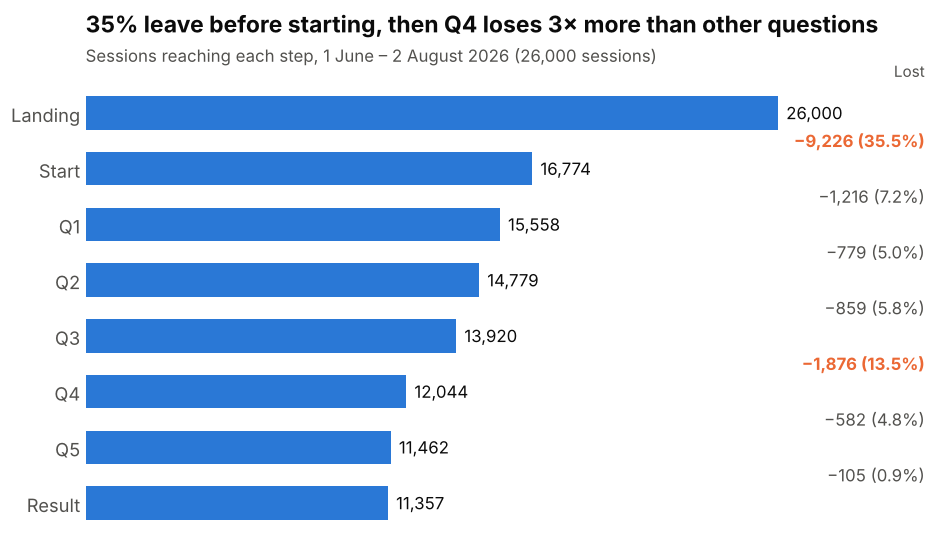

In [30]:
# Step 30: funnel chart (reuses the "funnel" table from step 20)
step_names = funnel["step"].str[3:]                     # "1. Landing" -> "Landing"
loss_pct = (funnel["lost"] / funnel["sessions"].shift(1) * 100).round(1)

fig, ax = plt.subplots()
y = range(len(funnel))[::-1]                             # first step at the top
ax.barh(y, funnel["sessions"], color=BLUE, height=0.6)   # horizontal bars

# Axes: keep only the step names
ax.set_yticks(list(y), step_names)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

# Labels: sessions at the end of each bar + loss on the right
for yi, v, lost, pct in zip(y, funnel["sessions"], funnel["lost"], loss_pct):
    ax.text(v + 300, yi, f"{v:,.0f}", va="center", fontsize=11)
    if pd.notna(lost):                                   # no loss for the first step
        big = pct > 10                                   # big loss -> orange and bold
        ax.text(31500, yi + 0.5, f"−{lost:,.0f} ({pct:.1f}%)",
                va="center", ha="right", fontsize=11,
                color=ORANGE if big else TEXT2, fontweight="bold" if big else "normal")

ax.set_xlim(0, 32000)
ax.text(31500, len(funnel) - 0.35, "Lost", ha="right", fontsize=10, color=TEXT2)
add_title(ax, "35% leave before starting, then Q4 loses 3× more than other questions",
          "Sessions reaching each step, 1 June – 2 August 2026 (26,000 sessions)")
save(fig, "01_funnel")
plt.show()

**How to read it:** each bar is the number of sessions still in the questionnaire at that step; the right column shows how many were lost since the previous step.

**Interpretation:**
- Two leaks stand out in orange: **the landing page (−35.5%)** and **Q4 (−13.5%)**. Every other step loses about 5%.
- The landing page alone accounts for 63% of all lost visitors: the first lever is to convince visitors to **start**.
- Inside the questionnaire, Q4 is the only question that breaks the pattern: it is the one to fix first.

## Step 31 – Chart 2: Q4 drop-off by device

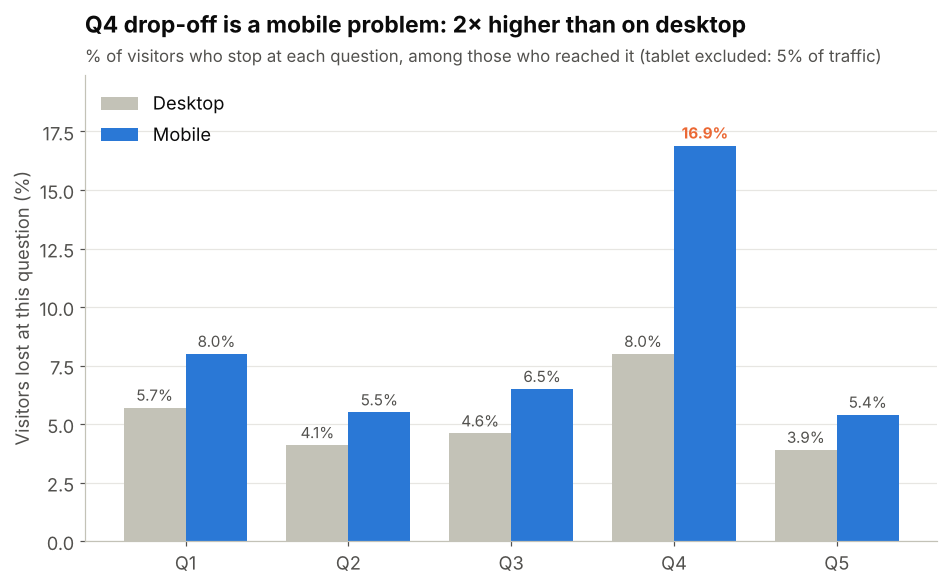

In [31]:
# Step 31: chart 2 – drop-off at each question, mobile vs desktop

# 1) SQL: drop-off rate (% of visitors lost) at each question, by device
drop = con.execute("""
    WITH steps AS (
        SELECT device_type,
               SUM(has_started::INT)                   AS start,
               SUM((nb_questions_answered >= 1)::INT)  AS q1,
               SUM((nb_questions_answered >= 2)::INT)  AS q2,
               SUM((nb_questions_answered >= 3)::INT)  AS q3,
               SUM((nb_questions_answered >= 4)::INT)  AS q4,
               SUM((nb_questions_answered >= 5)::INT)  AS q5
        FROM session_summary
        WHERE device_type IN ('mobile', 'desktop')
        GROUP BY device_type
    )
    SELECT device_type,
           ROUND(100 - 100.0 * q1 / start, 1) AS "Q1",
           ROUND(100 - 100.0 * q2 / q1,    1) AS "Q2",
           ROUND(100 - 100.0 * q3 / q2,    1) AS "Q3",
           ROUND(100 - 100.0 * q4 / q3,    1) AS "Q4",
           ROUND(100 - 100.0 * q5 / q4,    1) AS "Q5"
    FROM steps
""").df().set_index("device_type")

# 2) Grouped bar chart: one group per question, one bar per device
questions = list(drop.columns)
x = range(len(questions))
width = 0.38

fig, ax = plt.subplots()
ax.bar([i - width/2 for i in x], drop.loc["desktop"], width, color=GREY, label="Desktop")
ax.bar([i + width/2 for i in x], drop.loc["mobile"],  width, color=BLUE, label="Mobile")

# Value labels on top of each bar (bold + orange for the Q4 gap)
for i, q in enumerate(questions):
    for device, offset in [("desktop", -width/2), ("mobile", width/2)]:
        v = drop.loc[device, q]
        highlight = (q == "Q4" and device == "mobile")
        ax.text(i + offset, v + 0.3, f"{v:.1f}%", ha="center", fontsize=10,
                color=ORANGE if highlight else TEXT2, fontweight="bold" if highlight else "normal")

ax.set_xticks(list(x), questions)
ax.set_ylabel("Visitors lost at this question (%)")
ax.set_ylim(0, drop.values.max() + 3)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GREY, alpha=0.4); ax.set_axisbelow(True)
add_title(ax, "Q4 drop-off is a mobile problem: 2× higher than on desktop",
          "% of visitors who stop at each question, among those who reached it (tablet excluded: 5% of traffic)")
save(fig, "02_dropoff_by_device")
plt.show()

**How to read it:** for each question, the % of visitors who stopped there among those who reached it, on desktop (grey) and mobile (blue).

**Interpretation:**
- Mobile loses slightly more visitors at **every** question (+1 to +2 points): a normal "small screen / distraction" effect.
- **At Q4 the gap doubles: 16.9% on mobile vs 8.0% on desktop.** If Q4 were only uncomfortable to answer, it would lose as many people on both devices.
- The most likely cause is **how Q4 renders on mobile** (the only question with 4 options and long labels).
- **Action:** redesign Q4 for mobile (shorter labels, stacked full-width buttons). Since mobile is 65% of traffic, matching desktop at Q4 would add ~700 results over the period (+6%).

## Step 32 – Chart 3: volume vs completion by source

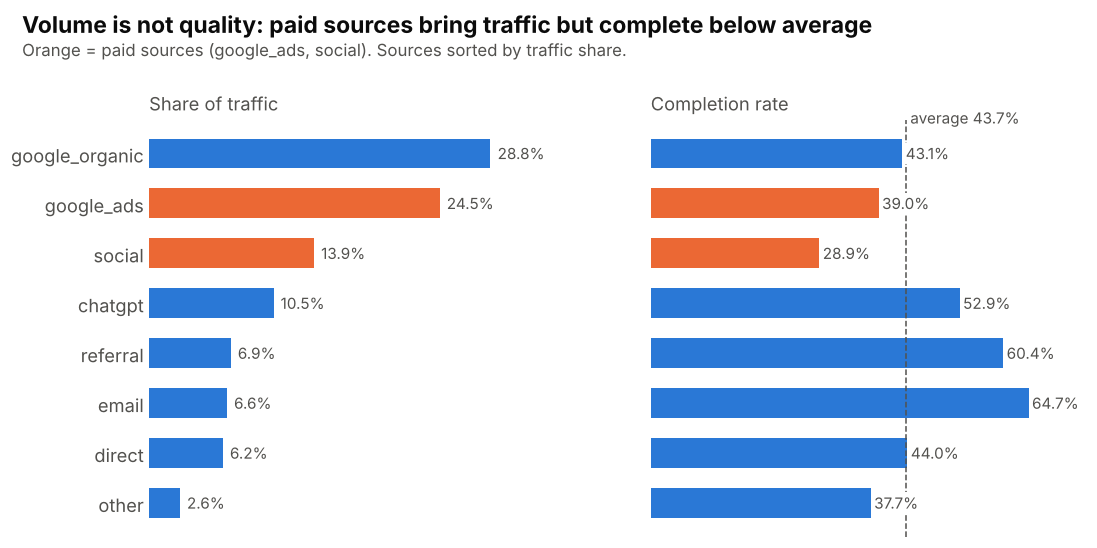

In [32]:
# Step 32: chart 3 – traffic share and completion rate by source (two panels, same order)

# 1) SQL
src = con.execute("""
    SELECT acquisition_source,
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS traffic_share,
           100.0 * AVG(is_completed::INT)           AS completion_rate
    FROM session_summary
    GROUP BY acquisition_source
    ORDER BY traffic_share
""").df()
avg_completion = 100 * con.execute("SELECT AVG(is_completed::INT) FROM session_summary").fetchone()[0]

# 2) Two side-by-side panels sharing the same source order
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(11, 5.5))
y = range(len(src))
paid = src["acquisition_source"].isin(["google_ads", "social"])     # paid sources = highlighted
colors = [ORANGE if p else BLUE for p in paid]

ax1.barh(y, src["traffic_share"], color=colors, height=0.6)
ax2.barh(y, src["completion_rate"], color=colors, height=0.6)
ax2.axvline(avg_completion, color=TEXT2, linestyle="--", linewidth=1)
ax2.text(avg_completion + 0.8, len(src) - 0.4, f"average {avg_completion:.1f}%", fontsize=10, color=TEXT2)

for ax, col in [(ax1, "traffic_share"), (ax2, "completion_rate")]:
    for yi, v in zip(y, src[col]):
        ax.text(v + 0.6, yi, f"{v:.1f}%", va="center", fontsize=10, color=TEXT2,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

ax1.set_yticks(list(y), src["acquisition_source"])
ax1.set_xlim(0, src["traffic_share"].max() + 8)
ax2.set_xlim(0, src["completion_rate"].max() + 10)
ax1.set_title("Share of traffic", fontsize=12, color=TEXT2, fontweight="normal")
ax2.set_title("Completion rate", fontsize=12, color=TEXT2, fontweight="normal")
fig.suptitle("Volume is not quality: paid sources bring traffic but complete below average",
             x=0.02, ha="left", fontsize=15, fontweight="bold")
fig.text(0.02, 0.905, "Orange = paid sources (google_ads, social). Sources sorted by traffic share.",
         fontsize=11, color=TEXT2)
fig.subplots_adjust(top=0.8, wspace=0.15)
save(fig, "03_sources_volume_vs_completion")
plt.show()

**How to read it:** the left panel shows how much traffic each source brings, the right panel how many of its visitors complete the questionnaire. Sources are in the same order in both panels.

**Interpretation:**
- The two biggest paid sources do not convert well: **google_ads (24.5% of traffic, 39.0% completion)** and especially **social (13.9% of traffic, 28.9% completion)**, the worst source.
- The best completion rates come from **small sources**: **email (64.7%)**, **referral (60.4%)** and **chatgpt (52.9%)**. These visitors arrive with a clear intent.
- **Takeaway:** a channel must not be judged on traffic alone. Chart 4 goes one step further and looks at the profiles each channel brings.

## Step 33 – Chart 4: at-risk profiles per 100 sessions, by campaign

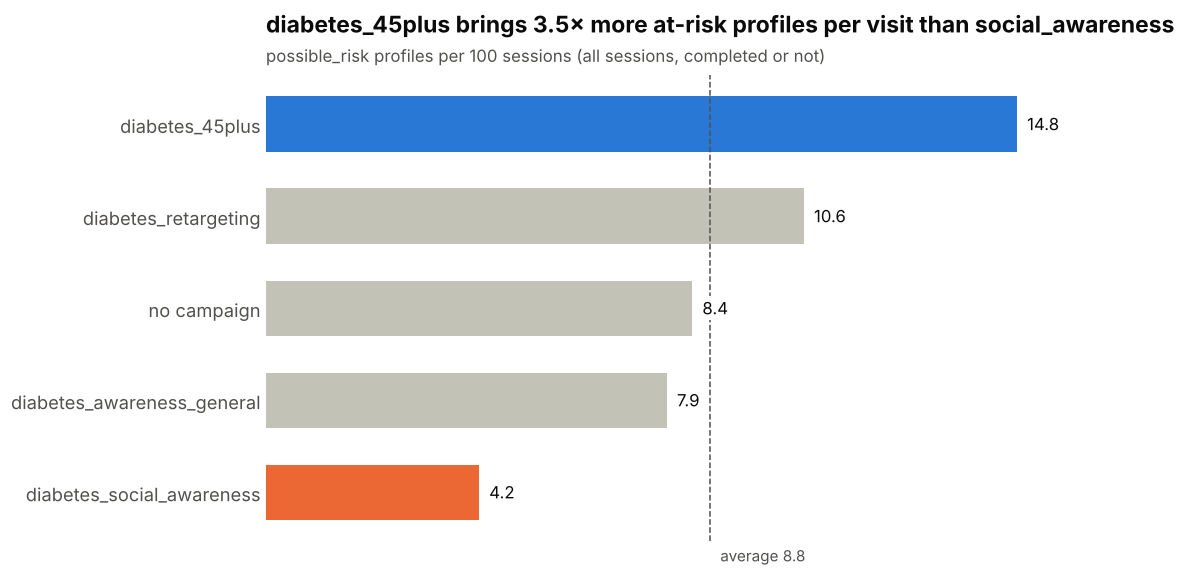

In [33]:
# Step 33: chart 4 – possible_risk profiles per 100 sessions, by campaign (reuses risk_per_100 from step 26)
camp = risk_per_100("campaign_name").sort_values("possible_risk per 100 sessions")
overall = 100 * con.execute(
    "SELECT AVG(COALESCE(outcome_category = 'possible_risk', FALSE)::INT) FROM session_summary").fetchone()[0]

# Colours: best campaign in blue, worst in orange, the rest in grey
def colour(name):
    return BLUE if name == "diabetes_45plus" else ORANGE if name == "diabetes_social_awareness" else GREY

fig, ax = plt.subplots()
y = range(len(camp))
values = camp["possible_risk per 100 sessions"]
ax.barh(y, values, color=[colour(c) for c in camp["campaign_name"]], height=0.6)
labels = camp["campaign_name"].replace({"none": "no campaign"})
ax.set_yticks(list(y), labels)
for yi, v in zip(y, values):
    ax.text(v + 0.2, yi, f"{v:.1f}", va="center", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax.axvline(overall, color=TEXT2, linestyle="--", linewidth=1)
ax.text(overall + 0.2, -0.75, f"average {overall:.1f}", fontsize=10, color=TEXT2)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, values.max() + 2)
add_title(ax, "diabetes_45plus brings 3.5× more at-risk profiles per visit than social_awareness",
          "possible_risk profiles per 100 sessions (all sessions, completed or not)")
save(fig, "04_risk_per_100_by_campaign")
plt.show()

**How to read it:** for 100 sessions brought by each campaign, how many end with a `possible_risk` result. It combines both losses (visitors who do not complete, and completers who are not at risk) into one number. The dashed line is the overall average (8.8).

**Interpretation:**
- **diabetes_45plus is by far the best campaign: 14.8 at-risk profiles per 100 sessions**, 1.7× the average. Its completion is low (37.5%), but 4 in 10 completers are at risk, because it reaches the 45+ population (91% of its visitors).
- **diabetes_social_awareness is the worst: 4.2**, half the average and 3.5× less than 45plus. It reaches a young audience that completes little and is rarely at risk.
- **Action:** shift budget from social_awareness to 45plus. Cost data per campaign is needed to turn this into a cost per at-risk profile.

## Step 34 – Chart 5: at-risk share by age group

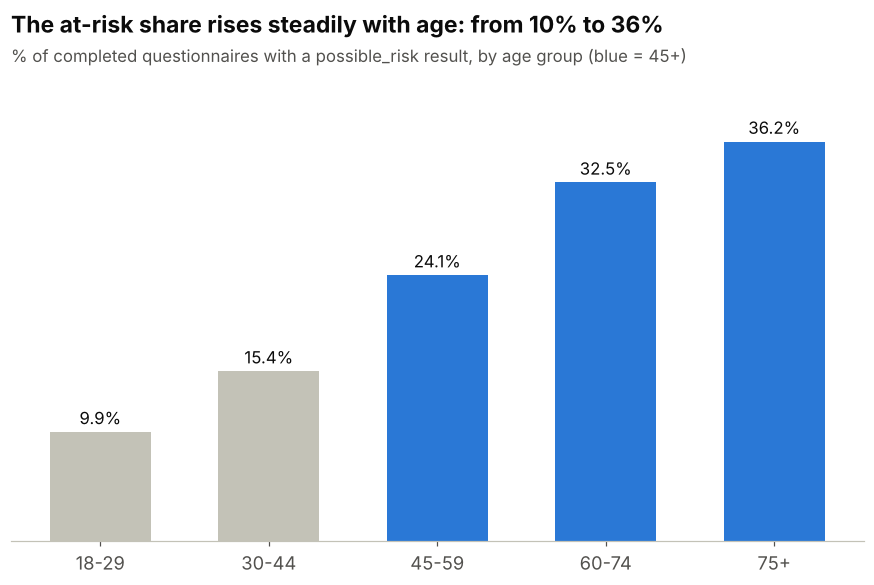

In [34]:
# Step 34: chart 5 – share of possible_risk by age group (reuses possible_risk_share from step 25)
age = possible_risk_share("age_group")
age = age[age["age_group"].isin(["18-29", "30-44", "45-59", "60-74", "75+"])]   # <18 (28 results) and unknown excluded

fig, ax = plt.subplots()
x = range(len(age))
colors = [BLUE if g in ("45-59", "60-74", "75+") else GREY for g in age["age_group"]]   # 45+ = target of the 45plus campaign
ax.bar(x, age["possible_risk %"], color=colors, width=0.6)
for xi, v in zip(x, age["possible_risk %"]):
    ax.text(xi, v + 0.7, f"{v:.1f}%", ha="center", fontsize=11)
ax.set_xticks(list(x), age["age_group"])
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_ylim(0, age["possible_risk %"].max() + 6)
add_title(ax, "The at-risk share rises steadily with age: from 10% to 36%",
          "% of completed questionnaires with a possible_risk result, by age group (blue = 45+)")
save(fig, "05_risk_by_age")
plt.show()

**How to read it:** among people who completed the questionnaire, the % who got a `possible_risk` result in each age group. Blue bars are the 45+ groups targeted by the `diabetes_45plus` campaign.

**Interpretation:**
- The at-risk share **rises steadily with age**: 9.9% (18–29) → 15.4% → 24.1% → 32.5% → **36.2% (75+)**, i.e. 3.5× more among the oldest.
- This is consistent with what is known about type 2 diabetes, which makes the data credible.
- It **explains chart 4**: targeting 45+ visitors mechanically brings more at-risk profiles. Age is the strongest targeting lever.
- Note: the under-18 group (28 results) is too small to conclude, and its presence in a health questionnaire should be flagged.

## Step 35 – Chart 6: weekly trend

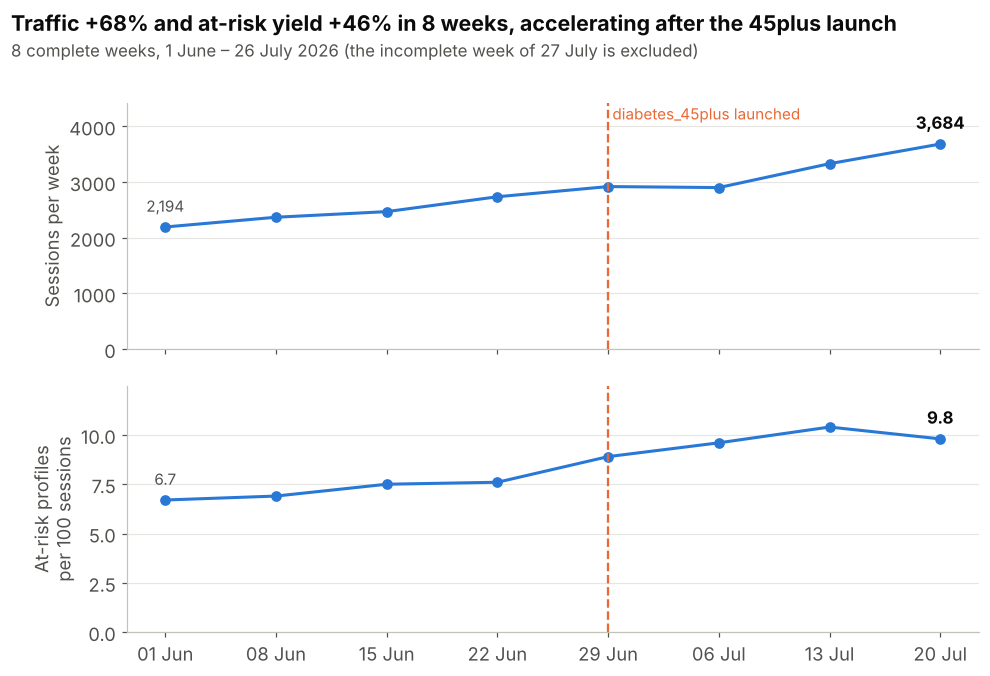

In [35]:
# Step 35: chart 6 – weekly sessions and at-risk yield (reuses the weekly table from step 27)
# Two stacked panels sharing the same x axis (never two y-axes on one chart)
launch = pd.Timestamp("2026-06-29")      # first week of diabetes_45plus (step 28)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6.5))
weeks = pd.to_datetime(weekly["week"])

ax1.plot(weeks, weekly["sessions"], color=BLUE, linewidth=2, marker="o", markersize=6)
ax2.plot(weeks, weekly["possible_risk per 100 sessions"], color=BLUE, linewidth=2, marker="o", markersize=6)

for ax, col, fmt in [(ax1, "sessions", "{:,.0f}"), (ax2, "possible_risk per 100 sessions", "{:.1f}")]:
    ax.axvline(launch, color=ORANGE, linestyle="--", linewidth=1.5)
    first, last = weekly[col].iloc[0], weekly[col].iloc[-1]
    ax.annotate(xy=(weeks.iloc[0], first), xytext=(0, 10), textcoords="offset points", text=fmt.format(first), ha="center", fontsize=10, color=TEXT2)
    ax.annotate(xy=(weeks.iloc[-1], last), xytext=(0, 10), textcoords="offset points", text=fmt.format(last), ha="center", fontsize=11, fontweight="bold")
    ax.grid(axis="y", color=GREY, alpha=0.4); ax.set_axisbelow(True)
    ax.set_ylim(0, weekly[col].max() * 1.2)

ax1.text(launch, weekly["sessions"].max() * 1.12, " diabetes_45plus launched", color=ORANGE, fontsize=10)
ax1.set_ylabel("Sessions per week")
ax2.set_ylabel("At-risk profiles\nper 100 sessions")
ax2.set_xticks(weeks, [w.strftime("%d %b") for w in weeks])
fig.suptitle("Traffic +68% and at-risk yield +46% in 8 weeks, accelerating after the 45plus launch",
             x=0.02, ha="left", fontsize=14, fontweight="bold")
fig.text(0.02, 0.915, "8 complete weeks, 1 June – 26 July 2026 (the incomplete week of 27 July is excluded)",
         fontsize=11, color=TEXT2)
fig.subplots_adjust(top=0.85, hspace=0.15)
save(fig, "06_weekly_trend")
plt.show()

**How to read it:** top panel = sessions per week, bottom panel = at-risk profiles per 100 sessions. The orange dashed line marks the first week of the `diabetes_45plus` campaign. Both panels share the same weeks (two separate charts rather than two y-axes on one chart, which would be misleading).

**Interpretation:**
- **Traffic grows by 68%** in 8 weeks (2,194 → 3,684 sessions/week).
- **Quality grows at the same time**: at-risk profiles go from 6.7 to 9.8 per 100 sessions (+46%). Usually more traffic means less engaged visitors; here both improve.
- **The quality jump starts the week 45plus is launched** (step 28: 45plus grows to ~22% of sessions while social_awareness falls from 17% to 10%). The July marketing reallocation appears to have worked.
- **Caution:** this is a correlation, not a proof. Other changes (e.g. to the page) may have happened at the same time; an A/B test would be needed to confirm it.

# Answers to the four questions

## 1. What are the most important findings?

1. **The landing page is the biggest leak: 35% of visitors leave without starting the questionnaire.** This represents 63% of all lost visitors. Overall, 43.7% of visitors reach a result (67.7% of those who start).
2. **Q4 (physical activity) is the main drop-off inside the questionnaire, and it is mostly a mobile problem.** 13.5% of visitors stop at Q4 vs ~5% at the other questions; on mobile it reaches 16.9% vs 8.0% on desktop. Mobile is 65% of traffic: fixing Q4 on mobile would add ~700 results over the period (+6%).
3. **Volume is not quality.** Paid sources bring the most traffic but complete below average (google_ads 39.0%, social 28.9%), while small sources complete best (email 64.7%, referral 60.4%, chatgpt 52.9%).
4. **The right metric is at-risk profiles per 100 sessions, and diabetes_45plus wins by far.** 1 in 5 completers gets `possible_risk`, and this share rises with age (9.9% → 36.2%). diabetes_45plus brings 14.8 at-risk profiles per 100 sessions vs 4.2 for diabetes_social_awareness (average 8.8).
5. **Performance improved over the period.** Traffic grew +68% and at-risk yield +46% in 8 weeks; the jump coincides with the launch of diabetes_45plus (week of 29 June) and the decline of social_awareness.
6. **The data is reliable after cleaning, with one major limit:** it only covers 1 June – 2 August 2026, not June–August.

## 2. Which questions remain unanswered?

- **Why do 35% of visitors leave the landing page?** We have no data on load time, scroll depth or time spent on the page.
- **Is the Q4 drop-off really a mobile display issue?** The device gap strongly suggests it, but only a UX review or an A/B test of a redesigned Q4 can confirm it.
- **Did diabetes_45plus cause the quality improvement?** It is a correlation in time; other changes (page, seasonality) may have happened at the same time.
- **What happens after the result?** We do not know whether `possible_risk` visitors book a consultation, which is the real business outcome for Doctoome.
- **Which channels are the most cost-efficient?** Without campaign costs, we cannot compute a cost per completion or per at-risk profile.
- **Why does the data stop on 2 August, with 1 August already abnormally low?** Extraction limit or tracking incident?
- **Are some attributions wrong?** 219 `direct` sessions carry a campaign, `other` is undefined, and 105 sessions answered all 5 questions without an outcome (abandonment or tracking bug).

## 3. What additional data would you collect?

| Data | Why |
|---|---|
| **Post-result actions**: click on "book a consultation", appointment booked, consultation held | Measure the real business conversion, especially for `possible_risk` profiles |
| **Campaign costs** (spend, impressions, clicks) | Compute cost per completion and cost per at-risk profile per channel |
| **Landing page behaviour**: load time, scroll depth, time on page, clicks on the start button, JS errors | Understand the 35% who leave before starting |
| **Questionnaire UX**: screen size, browser, "back" clicks, time spent per question | Confirm the mobile display hypothesis for Q4 |
| **Questionnaire / page version ID** | Run and analyse A/B tests properly |
| **Full UTM parameters** (source, medium, campaign, content, term) and referrer | Remove attribution ambiguities (`google`, `direct` with campaign, `other`, AI assistants) |
| **The complete August data** + tracking completeness logs | Analyse the full period and detect tracking incidents |
| **A short feedback question after the result** | Understand perceived usefulness and trust |
| **Age verification / consent** | Handle minors (42 visitors under 18) in a health questionnaire |

## 4. What would you track if the questionnaire stayed live for 12 months?

**North-star metric:** **at-risk (`possible_risk`) profiles per 100 sessions** — and, once tracked, **consultations booked per 100 sessions**.

| Area | KPIs |
|---|---|
| **Funnel** | Landing → start rate; completion rate (overall and among starters); drop-off rate per question; mobile vs desktop gap at Q4 |
| **Acquisition** | Sessions, completion rate and at-risk profiles per 100 sessions **by channel and campaign**; cost per completion and per at-risk profile (once costs are available); share of traffic from AI assistants |
| **Outcomes** | Distribution of the 3 categories; `possible_risk` share by age group; share of visitors aged 45+ |
| **Business** | Consultation booking rate among `possible_risk` profiles; booking → consultation held |
| **Data quality (alerts)** | Daily volume of events (alert on sudden drops, as on 1–2 August); % sessions with 5 answers but no outcome; % unmapped source values; % missing demographics; % duplicate answers |
| **Seasonality & tests** | Month-over-month trends (summer vs autumn, World Diabetes Day on 14 November); results of A/B tests on the landing page and Q4 |

**Cadence:** a weekly dashboard for the marketing and product teams, a monthly review of channel allocation, and automated alerts on data quality.